# 04 · Score Predictor: You vs the Machine

**How to play**
1. Pick a season (`SEASON`) and a gameweek (`GW`) in the settings cell.
2. Run the cells. The fixtures for that gameweek are listed.
3. Type your predicted scores in `my_picks`.
4. Run the reveal cell. The machine's picks and the real results are shown, and both of you are scored:
   **3 points** for the exact score, **1 point** for the right result (home win / draw / away win).
5. Change `GW` to the next gameweek and play again. Results are saved in `game/score_predictor.csv`.

**What the machine does:** the Poisson goal models from notebook 01 (last-5 form + Elo) give the expected
goals of each team. The machine then picks the scoreline with the most *expected points* under the 3/1 scoring.
It is trained **only on seasons before `SEASON`**, so it has never seen the matches you are playing.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))   # run from notebooks/, so "src" is one folder up
from src import pl

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)

In [2]:
# ---- settings ----
SEASON = "2025-26"     # any season from 2017-18 to 2025-26
GW = 1                # gameweek 1-38
PLAYER = "You"           # your name on the leaderboard

In [3]:
mdf, team_games, elo_hist = pl.build_match_table()
fixtures = pl.fpl_fixtures(pl.load_fpl([SEASON]))

train = mdf[mdf["Season"] < SEASON]
goal_models = pl.fit_goal_models(train)

# no leakage: every training match is before the first match of the season being played
assert train["Date"].max() < fixtures["Kickoff"].min()
print(f"Machine trained on {len(train)} matches ({train['Season'].min()} to {train['Season'].max()})")

Machine trained on 3420 matches (2016-17 to 2024-25)


In [4]:
gw_fx = fixtures[fixtures["GW"] == GW].merge(
    mdf[["Season", "Home_Team", "Away_Team"] + pl.MATCH_FEATURES], on=["Season", "Home_Team", "Away_Team"])
gw_fx["Match"] = gw_fx["Home_Team"] + " v " + gw_fx["Away_Team"]
gw_fx["Lam_Home"] = goal_models[0].predict(gw_fx[pl.MATCH_FEATURES])
gw_fx["Lam_Away"] = goal_models[1].predict(gw_fx[pl.MATCH_FEATURES])

print(f"{SEASON} gameweek {GW}: copy this into the next cell and fill in your scores\n")
print("my_picks = {")
for m in gw_fx["Match"]:
    print(f'    "{m}": (0, 0),')
print("}")

2025-26 gameweek 1: copy this into the next cell and fill in your scores

my_picks = {
    "Liverpool v Bournemouth": (0, 0),
    "Aston Villa v Newcastle": (0, 0),
    "Brighton v Fulham": (0, 0),
    "Sunderland v West Ham": (0, 0),
    "Tottenham v Burnley": (0, 0),
    "Wolves v Man City": (0, 0),
    "Nott'm Forest v Brentford": (0, 0),
    "Chelsea v Crystal Palace": (0, 0),
    "Man United v Arsenal": (0, 0),
    "Leeds v Everton": (0, 0),
}


### Your predictions

In [5]:
my_picks = {
    "Liverpool v Bournemouth": (2, 1),
    "Aston Villa v Newcastle": (1, 1),
    "Brighton v Fulham": (1, 0),
    "Sunderland v West Ham": (0, 2),
    "Tottenham v Burnley": (2, 0),
    "Wolves v Man City": (1, 2),
    "Nott'm Forest v Brentford": (2, 2),
    "Chelsea v Crystal Palace": (1, 0),
    "Man United v Arsenal": (1, 1),
    "Leeds v Everton": (3, 1),
}

### Reveal and score

In [6]:
rows = []
for r in gw_fx.itertuples():
    mh, ma = pl.best_pick(r.Lam_Home, r.Lam_Away)
    p_home, p_draw, p_away = pl.outcome_probs(r.Lam_Home, r.Lam_Away)
    yh, ya = my_picks.get(r.Match, (None, None))
    rows.append({
        "Match": r.Match,
        "You": f"{yh}-{ya}" if yh is not None else "no pick",
        "Machine": f"{mh}-{ma}",
        "Machine H/D/A %": f"{p_home:.0%} / {p_draw:.0%} / {p_away:.0%}",
        "Result": f"{r.Home_Goals}-{r.Away_Goals}",
        "Your pts": pl.score_points(yh, ya, r.Home_Goals, r.Away_Goals) if yh is not None else 0,
        "Machine pts": pl.score_points(mh, ma, r.Home_Goals, r.Away_Goals),
    })
reveal = pd.DataFrame(rows)
missing = set(my_picks) - set(gw_fx["Match"])
if missing:
    print("These picks are not fixtures of this gameweek (check spelling):", missing)
print(f"Gameweek {GW}:  {PLAYER} {reveal['Your pts'].sum()} pts  |  Machine {reveal['Machine pts'].sum()} pts")
reveal

Gameweek 1:  You 5 pts  |  Machine 7 pts


,Match,You,Machine,Machine H/D/A %,Result,Your pts,Machine pts
0,Liverpool v Bournemouth,2-1,2-0,66% / 19% / 15%,4-2,1,1
1,Aston Villa v Newcastle,1-1,0-1,37% / 25% / 37%,0-0,1,0
2,Brighton v Fulham,1-0,2-1,55% / 22% / 22%,1-1,0,0
3,Sunderland v West Ham,0-2,0-1,29% / 26% / 46%,3-0,0,0
4,Tottenham v Burnley,2-0,1-0,40% / 26% / 34%,3-0,1,1
5,Wolves v Man City,1-2,0-1,22% / 23% / 55%,0-4,1,1
6,Nott'm Forest v Brentford,2-2,1-0,40% / 26% / 34%,3-1,0,1
7,Chelsea v Crystal Palace,1-0,2-1,47% / 24% / 28%,0-0,0,0
8,Man United v Arsenal,1-1,0-1,31% / 25% / 44%,0-1,0,3
9,Leeds v Everton,3-1,0-1,25% / 25% / 50%,1-0,1,0


In [7]:
log = pd.concat([
    pd.DataFrame({"Season": SEASON, "GW": GW, "Match": reveal["Match"], "Player": PLAYER, "Pick": reveal["You"],
                  "Result": reveal["Result"], "Points": reveal["Your pts"]}),
    pd.DataFrame({"Season": SEASON, "GW": GW, "Match": reveal["Match"], "Player": "Machine", "Pick": reveal["Machine"],
                  "Result": reveal["Result"], "Points": reveal["Machine pts"]}),
])
history = pl.save_results(log, "score_predictor.csv", keys=["Season", "GW", "Match", "Player"])

### Leaderboard

Total points:
Player
Machine    7
You        5


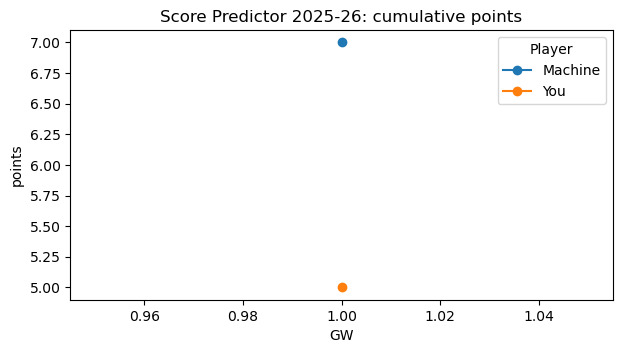

In [8]:
season_log = history[history["Season"] == SEASON]
per_gw = season_log.pivot_table(index="GW", columns="Player", values="Points", aggfunc="sum")
print("Total points:")
print(per_gw.sum().sort_values(ascending=False).to_string())

ax = per_gw.cumsum().plot(marker="o", figsize=(7, 3.5), title=f"Score Predictor {SEASON}: cumulative points")
ax.set_ylabel("points")
plt.show()

## How good is the machine? (backtest)

For every playable season, the machine predicts all 380 matches with a model trained only on earlier seasons.
It is compared with a simple baseline that always picks **1-0 to the home team**.

In [9]:
lam = pl.walk_forward_lambdas(mdf)
rows = []
for season, d in lam[lam["Season"].isin(pl.PLAYABLE_SEASONS)].groupby("Season"):
    picks = [pl.best_pick(h, a) for h, a in zip(d["Lam_Home"], d["Lam_Away"])]
    machine = [pl.score_points(p[0], p[1], h, a) for p, h, a in zip(picks, d["Home_Goals"], d["Away_Goals"])]
    base = [pl.score_points(1, 0, h, a) for h, a in zip(d["Home_Goals"], d["Away_Goals"])]
    rows.append({"Season": season, "Machine pts": sum(machine), "Baseline 1-0 pts": sum(base),
                 "Machine pts / GW": round(sum(machine) / 38, 2), "Exact scores": machine.count(3),
                 "Draw picks": sum(p[0] == p[1] for p in picks)})
backtest = pd.DataFrame(rows)
backtest

,Season,Machine pts,Baseline 1-0 pts,Machine pts / GW,Exact scores,Draw picks
0,2017-18,299,261,7.87,45,0
1,2018-19,298,239,7.84,35,0
2,2019-20,269,238,7.08,35,0
3,2020-21,265,210,6.97,39,0
4,2021-22,293,237,7.71,42,0
5,2022-23,281,276,7.39,39,0
6,2023-24,284,219,7.47,31,0
7,2024-25,282,213,7.42,39,0
8,2025-26,267,206,7.03,39,0


The machine almost never picks a draw: under 3/1 scoring a draw is rarely the pick with the most expected
points, because no single draw score is likely enough. Points also move a lot from season to season, so judge it
over many gameweeks, not one.